In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'core').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.figsize': (7, 4)})
FIG = ROOT / 'results' / 'figures'; DATA = ROOT / 'results' / 'data'

# 00 — Overview: strategy-proof allocation of two items without money, with and without complementarities

Course project (Auction Theory) on **Guo & Conitzer, AAMAS 2010**, *Strategy-proof Allocation of
Multiple Items between Two Agents without Payments or Priors*. Part A (the reading report) is in
`proposal/`. Part B — this repository — (i) replicates and sharpens the paper's numbers and
(ii) extends the model with a complementarity term $\varepsilon z_1z_2$ between the two goods.

Everything is reproducible: `core/` holds the code, `tests/` the regression tests, each
notebook is generated by a script in `experiments/` and executed so outputs are embedded.
Decisions and dead ends are in `docs/log.md`; proofs in `docs/theory/`.

## The model in one paragraph

Two agents, two divisible items, no money, no prior. Agent $i$ reports a type $(v,1-v)$ — her
values for the whole of item 1 and item 2 — and gets utility $v z_1+(1-v)z_2+\varepsilon z_1z_2$
from bundle $(z_1,z_2)$. A mechanism is $\alpha$-competitive if its welfare is at least
$\alpha$ times the first-best welfare at every type profile. The paper's **LIP(a)** mechanism
flips a coin, gives the winner one unit of artificial currency to spend against an increasing
price schedule $f(t)=at+b$, and gives the loser what is left.

## Results at a glance

### Additive valuations ($\varepsilon=0$) — notebooks 01, 02, 04

| Class of mechanisms | Paper | This project |
|---|---|---|
| LIP(2) | $\ge0.828$, $\le0.829$ | $\alpha(2)\in[0.8281462,0.8281472]$ (adaptive certified bracket) |
| best LIP(a) | — | $a^\star=2.1013$, $\alpha^\star=0.82939$; $\alpha(a)=\min\{\theta(a),\beta(a)\}$ with $\beta$ in closed form |
| any fixed-menu (swap-dictatorial, incl. all increasing-price) mechanism | — | **exactly $5/6=0.8333$**: four-line upper bound (Theorem A), attained by an explicit closed-form menu (Theorem C) |
| any strategy-proof mechanism | $\le0.841$ (LP, $N=50$) | the LP value *decreases* with $N$: $\le0.8368$ ($N=150$), extrapolating to $\approx0.8346$; small explicit certificates |

So the hierarchy is pinned down to within a percent: LIP $0.8294 <$ menus $= 0.8333 \le$ all SP $\lesssim 0.835$.

### Complementarities ($\varepsilon>0$) — notebooks 03, 04, 05

* First best $=1+\max\{\varepsilon,|x-y|\}$; "take-all" (fair coin, winner takes everything) is
  first best for $\varepsilon\ge1$.
* Fixed-menu mechanisms stay strategy-proof: the **$\varepsilon$-aware LIP(a)** lets the mechanism
  compute the dictator's $\varepsilon$-optimal bundle. The chatbot draft's "strategic LIP" is this
  mechanism in disguise (P5). Certified brackets for its ratio (P3–P4).
* **Nested (comonotone) lotteries** are a free improvement: give the dictator item $j$ iff
  $U<m_j$ with one uniform $U$. Nested LIP is first best for $\varepsilon\ge1$ and essentially the
  best menu mechanism for $\varepsilon\ge0.5$.
* **Upper bound on every strategy-proof mechanism** via an LP over lottery moments
  $(\mathbb E z_1,\mathbb E z_2,\mathbb E z_1z_2)$ and the McCormick envelope (P7).
* **Upper bound on every fixed-menu mechanism**, closed form (Theorem B):
  $\min\{(5+2\varepsilon)/6,\ (1+\varepsilon)/(1+2\varepsilon-\varepsilon^2)\}$, exact for
  $\varepsilon\ge0.3$ and attained for $\varepsilon\ge\tfrac12$ by the *modest dictator* menu
  "take $s^\star=(1-\varepsilon^2)/(1+2\varepsilon-\varepsilon^2)$ of your favourite item".
* **Price of dictatorship**: with complementarities the best mechanisms must pool when agents
  agree and split when they disagree, which no fixed-menu rule can do; the gap between the two
  bounds is $\approx0.1$ at $\varepsilon=\tfrac12$ (0.857 vs 0.951).
* **A non-dictatorial mechanism** (Propositions D, E): "split if strongly opposed
  ($x\ge\tfrac{1+\varepsilon}2$, $y\le\tfrac{1-\varepsilon}2$), else a modest dictator" is strategy-proof
  with ratio $2(1+\varepsilon)^2/(3+3\varepsilon+2\varepsilon^2)$ ($\varepsilon\le\tfrac12$) and
  $(1+\varepsilon)^2/(1+3\varepsilon)$ ($\varepsilon\ge\tfrac12$) — 0.900 at $\varepsilon=\tfrac12$ — beating every
  menu for $\varepsilon>0.366$.

### The naive rule — notebook 05

Keeping the additive report$\to$bundle rule when $\varepsilon>0$ is not strategy-proof; gains
from misreporting are bounded by $\varepsilon Q(\tfrac12)^2/2$ and truthful welfare collapses like
$1/(1+\varepsilon)$. Since strategic play reproduces the $\varepsilon$-aware mechanism anyway, the
fix is free.

## Figures

01_alpha_of_a.png


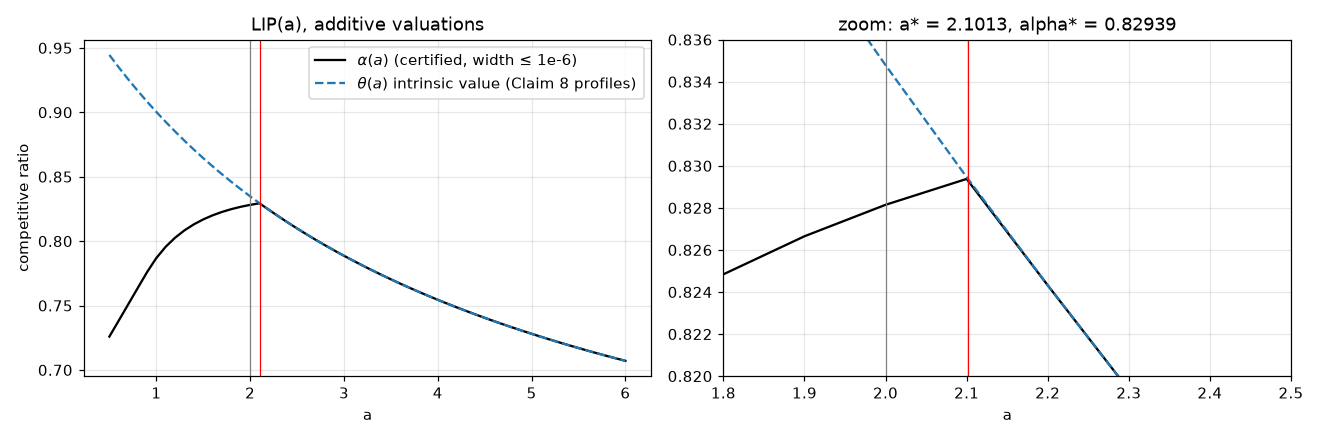

02_binding_profiles.png


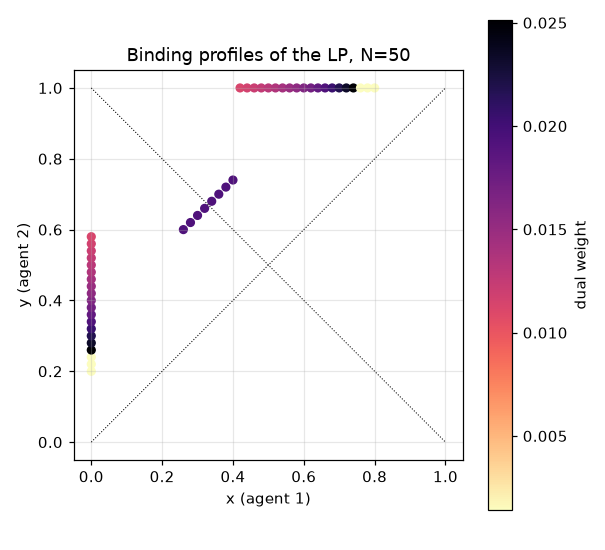

03_eps_overview.png


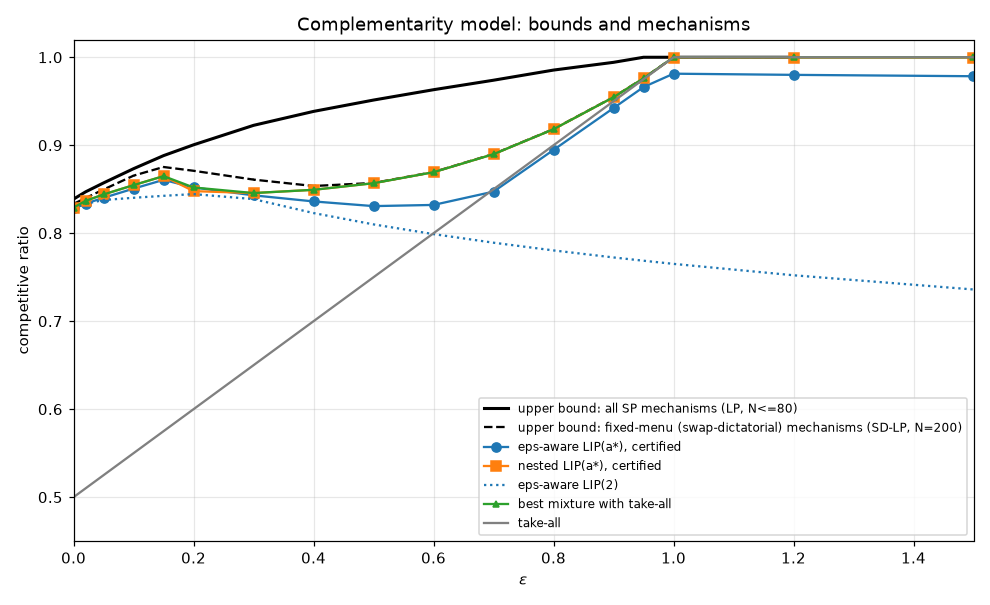

04_optimal_menu.png


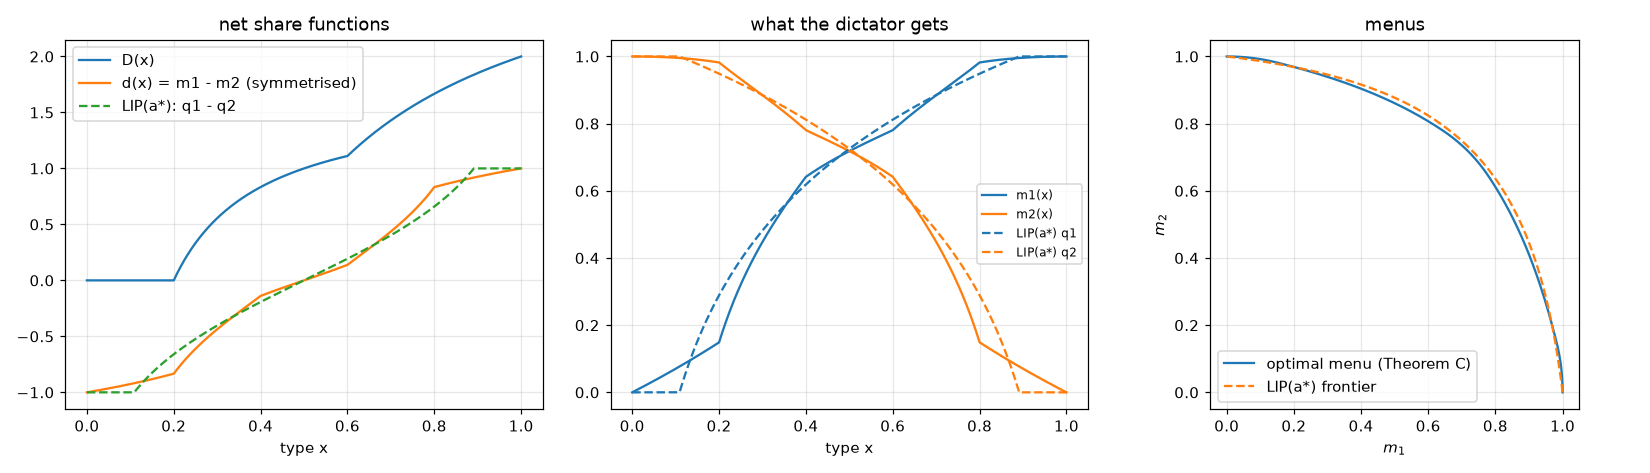

04_beyond_dictatorship.png


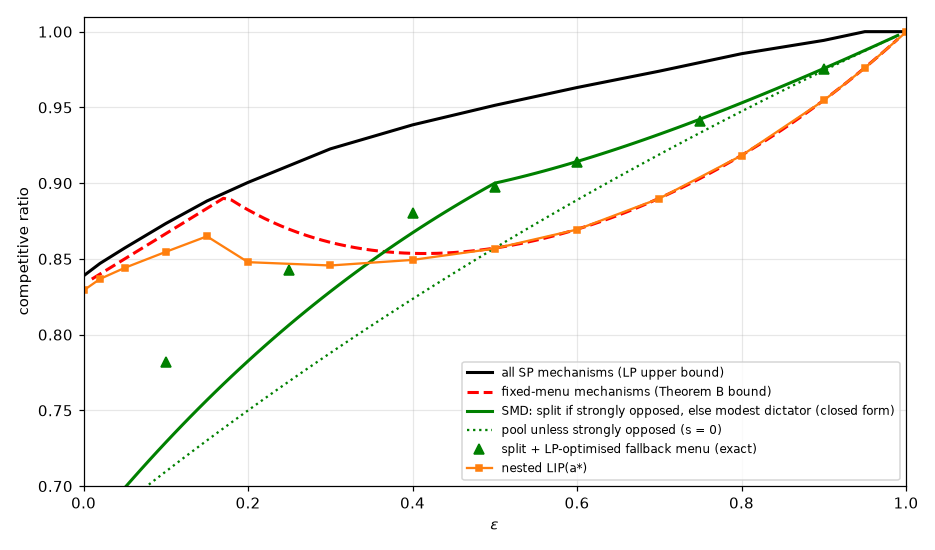

In [2]:
from IPython.display import Image, display
for f in ("01_alpha_of_a.png", "02_binding_profiles.png", "03_eps_overview.png", "04_optimal_menu.png", "04_beyond_dictatorship.png"):
    p = FIG / f
    if p.exists():
        print(f); display(Image(filename=str(p), width=760))

## Status of each claim

| Claim | Status |
|---|---|
| Replication of Theorems 1–3, Figure 1 | reproduced (tests in `tests/`) |
| $\alpha(2)$ bracket, $a^\star$ | certified numerics (rigorous lower bounds + exact upper bounds) |
| $\alpha(a)=\min\{\theta,\beta\}$ | both are proved upper bounds; equality verified numerically to $10^{-6}$ |
| LP bound decreases with $N$ | computed; limit extrapolated, not proved |
| Theorems A, C (menus $=5/6$), Theorem B (closed forms with $\varepsilon$) | proved (`docs/theory/03`); discretised Theorem-C menus evaluated exactly (0.83328 with 8001 items) |
| Propositions D, E (SMD mechanism) | proved (`docs/theory/04`) + brute-force incentive checks |
| P1–P7 of the $\varepsilon$ model | proved (`docs/theory/02`) |
| Price-of-dictatorship gap | LP upper bound (rigorous for grid-restricted types) vs exact SD values |

## Open questions we would pursue next

1. A strategy-proof mechanism approaching the SP-LP bound for $0<\varepsilon<1$: SMD closes
   part of the gap (0.900 vs 0.951 at $\varepsilon=\tfrac12$); the LP-optimal mechanisms use smooth,
   type-dependent pooling probabilities whose off-grid incentive compatibility is delicate.
2. The limit of the Theorem-1 LP as $N\to\infty$ ($\approx0.8346$) in closed form, and whether a
   non-dictatorial mechanism beats $5/6$ in the additive model.
3. Proving that LIP's worst case always lies on the edge or the anti-diagonal.
4. Substitutes with free disposal (notebook 06 is only a sketch); three or more items with $\varepsilon$.